# exp09: Konteks Temporal Kausal

Membandingkan clean tanpa history dengan rolling mean dan perubahan satu langkah pada tiga atau lima window. Riwayat hanya memakai current/past dan direset saat identitas/sesi/soal berubah, konteks kosong atau mixed, waktu tidak meningkat, atau gap melebihi 7,5 detik. Semua row tetap dievaluasi.

Dataset: good_acceptable, window 25 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp09"
WINDOW = "window_25s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_25s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,666
1,Medium,968
2,High,1077


,id,model,scaler,temporal,tune,variant,candidate_count
0,xgboost_history0,xgboost,standard,0,False,clean,1
1,xgboost_history3,xgboost,standard,3,False,clean,1
2,xgboost_history5,xgboost,standard,5,False,clean,1
3,logistic_history0,logistic,standard,0,False,clean,1
4,logistic_history3,logistic,standard,3,False,clean,1
5,logistic_history5,logistic,standard,5,False,clean,1


2711 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,2419,292,3
1,fold_01,Andreas,2566,145,3
2,fold_02,Athaya,2490,221,3
3,fold_03,Fabian,2437,274,3
4,fold_04,Rafi,2413,298,3
5,fold_05,Savitri,2453,258,3
6,fold_06,Shakilla,2617,94,3
7,fold_07,Tio,2465,246,3
8,fold_08,faqih,2446,265,3
9,fold_09,ikhsan,2499,212,3


exp09 / 25s / 1/78 / fold_00 / xgboost_history0


exp09 / 25s / 2/78 / fold_00 / logistic_history0


exp09 / 25s / 3/78 / fold_00 / logistic_history3


exp09 / 25s / 4/78 / fold_00 / logistic_history5


exp09 / 25s / 5/78 / fold_01 / xgboost_history0


... (72 outputs left out)

exp09 / 25s / 78/78 / fold_12 / xgboost_history3


            model  accuracy  balanced_accuracy  macro_f1  windows
logistic_history0  0.307636           0.323051  0.307433     2711
logistic_history3  0.313169           0.328892  0.312781     2711
logistic_history5  0.312800           0.328722  0.312220     2711
 xgboost_history0  0.296938           0.300496  0.295557     2711
 xgboost_history3  0.360752           0.365246  0.362708     2711
 xgboost_history5  0.364441           0.368222  0.367569     2711


Completed: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp09\window_25s_step_5s\full_5cbccb9a6cd6


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp09\window_25s_step_5s\full_5cbccb9a6cd6


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
5,xgboost_history5,0.364441,0.368222,0.367569,2711
4,xgboost_history3,0.360752,0.365246,0.362708,2711
1,logistic_history3,0.313169,0.328892,0.312781,2711
2,logistic_history5,0.312800,0.328722,0.312220,2711
0,logistic_history0,0.307636,0.323051,0.307433,2711
3,xgboost_history0,0.296938,0.300496,0.295557,2711


,scope,model,label,precision,recall,f1,support
0,pooled,logistic_history0,Low,0.243336,0.424925,0.309459,666
1,pooled,logistic_history0,Medium,0.370546,0.322314,0.344751,968
2,pooled,logistic_history0,High,0.338527,0.221913,0.268087,1077
42,pooled,logistic_history3,Low,0.248490,0.432432,0.315616,666
43,pooled,logistic_history3,Medium,0.372229,0.329545,0.349589,968
44,pooled,logistic_history3,High,0.348201,0.224698,0.273138,1077
84,pooled,logistic_history5,Low,0.249567,0.432432,0.316484,666
85,pooled,logistic_history5,Medium,0.371264,0.333678,0.351469,968
86,pooled,logistic_history5,High,0.344978,0.220056,0.268707,1077
126,pooled,xgboost_history0,Low,0.243429,0.319820,0.276444,666


accuracy                     balanced_accuracy            \
                        min    median       max               min    median   
model                                                                         
logistic_history0  0.026667  0.292683  0.712766          0.035070  0.354316   
logistic_history3  0.040000  0.300813  0.712766          0.046790  0.360196   
logistic_history5  0.037736  0.300813  0.765957          0.041471  0.357724   
xgboost_history0   0.021277  0.298013  0.453020          0.089015  0.289992   
xgboost_history3   0.074468  0.369811  0.520362          0.153173  0.370638   
xgboost_history5   0.085106  0.386179  0.476821          0.159574  0.380662   

                             macro_f1                      
                        max       min    median       max  
model                                                      
logistic_history0  0.492112  0.050231  0.227285  0.467806  
logistic_history3  0.513865  0.060632  0.206151  0.489985  
logistic_history5  0.534441  0.055234  0.218686  0.511109  
xgboost_history0   0.399392  0.122347  0.256745  0.349227  
xgboost_history3   0.501253  0.168920  0.300687  0.478776  
xgboost_history5   0.466740  0.166667  0.344293  0.426703

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

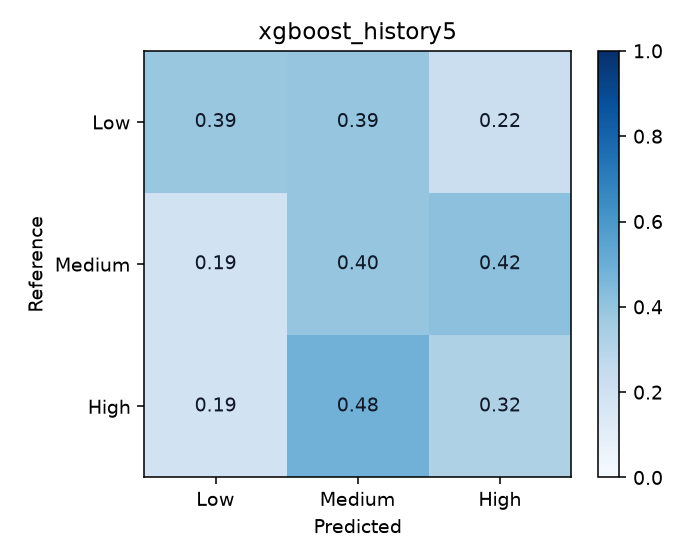

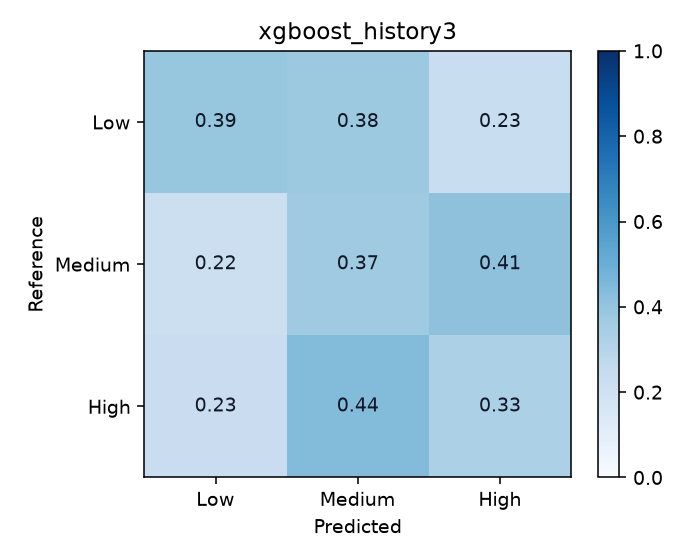

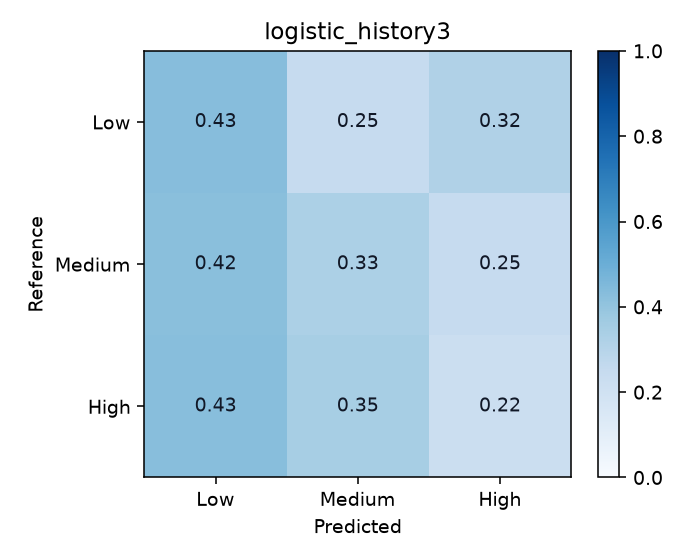

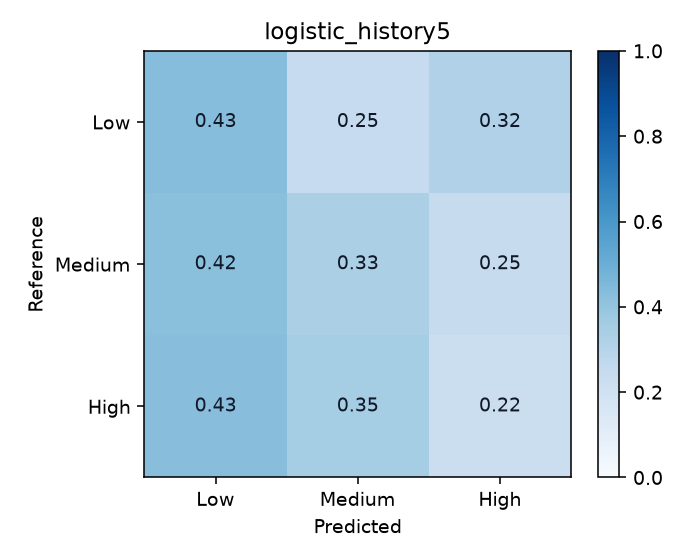

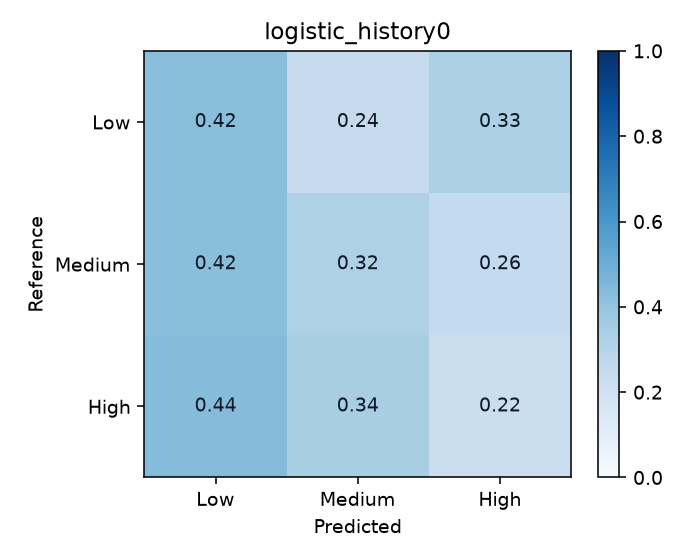

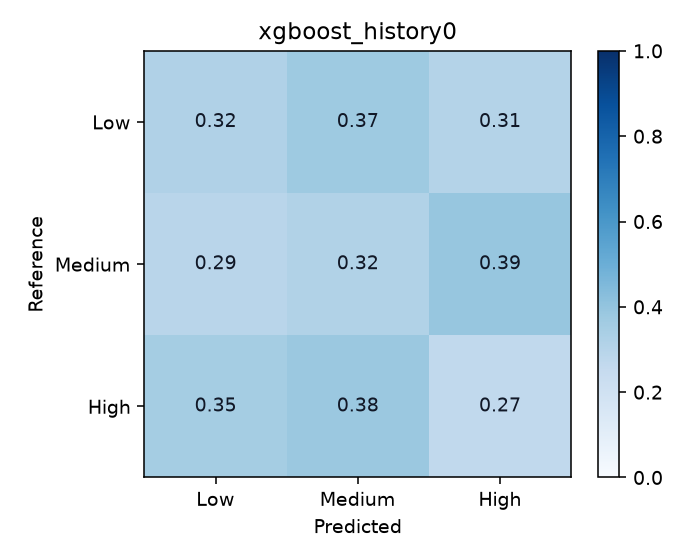

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [6]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp09\window_25s_step_5s\full_5cbccb9a6cd6
